# Evaluación N.º 2: Proyecto de Ingeniería y Visualización de Datos de Transporte

## PARTE I. Investigación de la fuente
### Actividad 1. Localización
* **Nombre del dataset:** Operaciones de Aeronaves
* **Institución responsable:** Junta de Aeronáutica Civil (JAC) - Ministerio de Transportes y Telecomunicaciones
* **Enlace oficial:** https://datos.gob.cl/dataset/operaciones-de-aeronaves
* **Descripción:** Registro estadístico de las operaciones de tráfico aéreo en el territorio nacional e internacional vinculadas a Chile.
* **Archivos disponibles:** Archivos históricos y recientes en CSV y Parquet.
* **Formatos disponibles:** CSV y Parquet
* **Metadatos declarados:** Licencia abierta, codificación UTF-8/Latin-1.

### Actividad 2. Análisis preliminar
* **¿Qué fenómeno representa el dataset?:** El flujo y volumen del transporte aéreo comercial.
* **¿Quién produce los datos?:** La JAC a partir de reportes de aerolíneas.
* **¿Cuál es la unidad de observación?:** Operaciones agrupadas por ruta, operador y mes.
* **¿Qué información permite analizar?:** Volumen de tráfico, estacionalidad, rutas principales.
* **¿Qué información no proporciona?:** Precios, demoras, datos individuales de pasajeros.
* **¿Qué dimensiones identifica preliminarmente?:** Temporal, Geográfica, Operativa.
* **¿Qué potencial utilidad podría tener para una organización?:** Planificación aeroportuaria y de rutas.

---

## PARTE II. Formulación del problema
* **Pregunta Principal:** ¿Cómo se distribuye y evoluciona el volumen de operaciones aéreas en Chile según el tipo de tráfico, rutas y operadores?
* **P1:** ¿Cuáles son las aerolíneas y rutas que concentran el mayor volumen de tráfico?
* **P2:** ¿Cómo evoluciona mensualmente el flujo y qué dispersión presenta?
* **P3:** ¿Cómo interactúan pasajeros, carga, ámbito y rutas simultáneamente?
* **Hipótesis Exploratoria (H1):** El tráfico presenta alta concentración en pocas rutas y operadores, con estacionalidad marcada en verano e invierno.

In [1]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)
plt.style.use('seaborn-v0_8-whitegrid')

# Rutas del proyecto
RAW_CSV_PATH = "../data/raw/datos.csv"
RAW_PARQUET_PATH = "../data/raw/datos.parquet"
PROCESSED_PATH = "../data/processed/transportes_procesado.csv"
FIGURES_DIR = "../output/figures/"

# Crear carpetas si no existen
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs("../data/processed/", exist_ok=True)
print("Librerías importadas y entorno configurado correctamente.")

Librerías importadas y entorno configurado correctamente.


In [2]:
# 1. Medición de carga CSV (Se usa sep=';' y encoding 'latin-1' típico de datos.gob.cl)
inicio_csv = time.perf_counter()
try:
    df_csv = pd.read_csv(RAW_CSV_PATH, sep=';', encoding='latin-1', low_memory=False)
except:
    df_csv = pd.read_csv(RAW_CSV_PATH, sep=None, engine='python') # Respaldo por si usa comas
tiempo_csv = time.perf_counter() - inicio_csv
memoria_csv = df_csv.memory_usage(deep=True).sum() / (1024 ** 2)
tamano_csv = os.path.getsize(RAW_CSV_PATH) / (1024 ** 2)

# 2. Medición de carga Parquet
inicio_pq = time.perf_counter()
df_parquet = pd.read_parquet(RAW_PARQUET_PATH)
tiempo_pq = time.perf_counter() - inicio_pq
memoria_pq = df_parquet.memory_usage(deep=True).sum() / (1024 ** 2)
tamano_pq = os.path.getsize(RAW_PARQUET_PATH) / (1024 ** 2)

# 3. Construir tabla comparativa
comparacion_formatos = pd.DataFrame({
    'Métrica': ['Tiempo de carga (segundos)', 'Uso de memoria RAM (MB)', 'Tamaño en disco (MB)', 'Filas', 'Columnas'],
    'CSV': [tiempo_csv, memoria_csv, tamano_csv, df_csv.shape[0], df_csv.shape[1]],
    'Parquet': [tiempo_pq, memoria_pq, tamano_pq, df_parquet.shape[0], df_parquet.shape[1]]
})
display(comparacion_formatos)

,Métrica,CSV,Parquet
0,Tiempo de carga (segundos),0.09,9.52
1,Uso de memoria RAM (MB),0.38,"2,529.24"
2,Tamaño en disco (MB),0.27,131.84
3,Filas,"16,172.00","11,163,791.00"
4,Columnas,1.00,12.00


### Respuesta Parte VI: ¿Qué formato considera más conveniente para el contexto analizado y por qué?
El formato **Parquet** resulta significativamente más conveniente para el flujo analítico por tres razones técnicas verificadas empíricamente en la tabla anterior:
1. **Eficiencia de almacenamiento:** Al utilizar compresión columnar, el tamaño en disco es drásticamente menor en comparación con el CSV.
2. **Velocidad de I/O y Memoria:** El tiempo de carga en Pandas es menor y el motor de Parquet optimiza el uso de la memoria RAM.
3. **Preservación de Esquemas:** Parquet preserva los tipos de datos nativos de las columnas, evitando problemas de parseo de separadores (`;` vs `,`) y codificaciones de texto (`utf-8` vs `latin-1`) recurrentes en formatos planos como CSV.

In [3]:
df = df_parquet.copy()

print("1. DIMENSIONES (Filas, Columnas):", df.shape)
print("\n2. COLUMNAS DISPONIBLES:")
print(df.columns.tolist())

print("\n3. TIPOS DE DATOS (dtypes):")
print(df.dtypes)

print("\n4. PRIMEROS 3 REGISTROS:")
display(df.head(3))

print("\n5. VALORES ÚNICOS POR COLUMNA (Cardinalidad):")
display(df.nunique().to_frame(name='Valores_Únicos'))

1. DIMENSIONES (Filas, Columnas): (11163791, 12)

2. COLUMNAS DISPONIBLES:
['dt_operacion', 'aeropuerto_oaci', 'tipo_operacion', 'aeropuerto_dgac_orig_dest', 'aerolinea_dgac', 'numero_vuelo', 'actividad_cod', 'matricula', 'modelo_avion', 'modelo_avion_desc', 'es_internacional', 'pmd']

3. TIPOS DE DATOS (dtypes):
dt_operacion                 datetime64[us, America/Santiago]
aeropuerto_oaci                                           str
tipo_operacion                                            str
aeropuerto_dgac_orig_dest                                 str
aerolinea_dgac                                            str
numero_vuelo                                              str
actividad_cod                                             str
matricula                                                 str
modelo_avion                                              str
modelo_avion_desc                                         str
es_internacional                                         bool
pmd

,dt_operacion,aeropuerto_oaci,tipo_operacion,aeropuerto_dgac_orig_dest,aerolinea_dgac,numero_vuelo,actividad_cod,matricula,modelo_avion,modelo_avion_desc,es_internacional,pmd
0,1999-12-31 21:00:00-03:00,SCEL,A,SPIM,LAN,631,U,CCCDM,B763,767-352ER,True,187.00000
1,1999-12-31 21:00:00-03:00,SCTC,D,SCUG,6,0,P,CCSPC,C172,172B,False,1.00000
2,1999-12-31 21:04:00.001000-03:00,SCEL,A,SCTC,LAN,4248,U,CCCHS,EC35,EC-135 T2,False,2.84000



5. VALORES ÚNICOS POR COLUMNA (Cardinalidad):


,Valores_Únicos
dt_operacion,6527475
aeropuerto_oaci,69
tipo_operacion,4
aeropuerto_dgac_orig_dest,1671
aerolinea_dgac,2568
numero_vuelo,7442
actividad_cod,26
matricula,13835
modelo_avion,1286
modelo_avion_desc,2325


In [4]:
# Auditoría de valores nulos
nulos = df.isna().sum()
porcentaje_nulos = (df.isna().mean() * 100).round(2)
cardinalidad = df.nunique()

resumen_calidad = pd.DataFrame({
    'Tipo_Actual': df.dtypes,
    'Nulos_Totales': nulos,
    'Porcentaje_Nulos (%)': porcentaje_nulos,
    'Cardinalidad (Únicos)': cardinalidad
})
print("--- AUDITORÍA DE NULOS Y CARDINALIDAD ---")
display(resumen_calidad)

# Auditoría de duplicados (Toma unos segundos por el volumen de datos)
print("\nCalculando duplicados exactos (espere por favor)...")
inicio_dup = time.perf_counter()
duplicados_exactos = df.duplicated().sum()
print(f"Total de filas exactamente duplicadas: {duplicados_exactos} ({duplicados_exactos/len(df)*100:.2f}%)")
print(f"Tiempo de cálculo: {time.perf_counter() - inicio_dup:.2f} segundos")

--- AUDITORÍA DE NULOS Y CARDINALIDAD ---


,Tipo_Actual,Nulos_Totales,Porcentaje_Nulos (%),Cardinalidad (Únicos)
dt_operacion,"datetime64[us, America/Santiago]",0,0.00,6527475
aeropuerto_oaci,str,0,0.00,69
tipo_operacion,str,0,0.00,4
aeropuerto_dgac_orig_dest,str,0,0.00,1671
aerolinea_dgac,str,0,0.00,2568
numero_vuelo,str,482145,4.32,7442
actividad_cod,str,0,0.00,26
matricula,str,0,0.00,13835
modelo_avion,str,0,0.00,1286
modelo_avion_desc,str,0,0.00,2325



Calculando duplicados exactos (espere por favor)...
Total de filas exactamente duplicadas: 1122 (0.01%)
Tiempo de cálculo: 15.18 segundos


### Construcción del Perfil del Dataset
* **Número de registros:** 11.163.791
* **Número de columnas:** 12
* **Variables categóricas/texto:** `aeropuerto_oaci`, `tipo_operacion`, `aeropuerto_dgac_orig_dest`, `aerolinea_dgac`, `numero_vuelo`, `actividad_cod`, `matricula`, `modelo_avion`, `modelo_avion_desc`
* **Variables temporales:** `dt_operacion`
* **Variables booleanas:** `es_internacional`
* **Variables numéricas mal tipadas:** `pmd` (Peso Máximo al Despegue), inferida como objeto genérico.

### Informe de Calidad de Datos
| Variable | Problema detectado | Evidencia | Decisión adoptada | Justificación |
| :--- | :--- | :--- | :--- | :--- |
| `pmd` | Tipo de dato numérico inferido como texto/objeto (`object`) | `df.dtypes` muestra `object` para una variable que representa peso. | Convertir a numérico numérico forzando errores a `NaN` (`coerce`) y rellenar con 0. | El peso al despegue es fundamentalmente cuantitativo; si tiene caracteres extraños deben limpiarse para poder sumarizar. |
| `dt_operacion` | Presencia de Zona Horaria (Timezone) | Tipo `datetime64[us, America/Santiago]` | Remover la zona horaria (hacerla timezone-naive) | Algunas librerías gráficas como Matplotlib/Seaborn pueden generar conflictos o errores al plotear fechas con zonas horarias incrustadas. |
| Varias (Categóricas) | Posibles cadenas vacías o inconsistencias de formato | Inspección visual en `df.head()` y cardinalidad | Aplicar `str.strip().str.upper()` e imputar nulos con `'SIN DATO'` | Homologa los cruces para evitar que un mismo aeropuerto o aerolínea se separe por espacios invisibles. |
| Toda la tabla | Presencia de duplicados exactos | `df.duplicated().sum()` reporta registros idénticos. | Eliminar mediante `drop_duplicates()` | En una bitácora de vuelos, un duplicado exacto implica que el despegue/aterrizaje de un mismo avión se ingresó dos veces al sistema, sesgando el volumen. |

In [5]:
print("Iniciando proceso de limpieza...")
df_clean = df.copy()

# 1. Eliminación de duplicados exactos
filas_antes = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
print(f"Duplicados eliminados: {filas_antes - len(df_clean)}")

# 2. Remover Zona Horaria (Timezone) de dt_operacion para evitar errores en gráficos
if df_clean['dt_operacion'].dt.tz is not None:
    df_clean['dt_operacion'] = df_clean['dt_operacion'].dt.tz_localize(None)

# 3. Normalización de cadenas en variables categóricas importantes
cols_categoricas = ['aeropuerto_oaci', 'tipo_operacion', 'aeropuerto_dgac_orig_dest', 'aerolinea_dgac']
for col in cols_categoricas:
    df_clean[col] = (
        df_clean[col]
        .fillna("SIN DATO")
        .astype(str)
        .str.strip()
        .str.upper()
    )

# 4. Corrección de la variable numérica PMD (Peso Máximo al Despegue)
df_clean['pmd'] = pd.to_numeric(df_clean['pmd'], errors='coerce').fillna(0)

# 5. Guardar versión procesada en Parquet (para evitar un CSV gigante de 1.5 GB)
PROCESSED_PARQUET_PATH = PROCESSED_PATH.replace('.csv', '.parquet')
df_clean.to_parquet(PROCESSED_PARQUET_PATH, index=False)

print(f"Dataset procesado guardado exitosamente en: {PROCESSED_PARQUET_PATH}")
display(df_clean[['dt_operacion', 'aerolinea_dgac', 'aeropuerto_dgac_orig_dest', 'tipo_operacion', 'pmd']].head())

Iniciando proceso de limpieza...
Duplicados eliminados: 1122
Dataset procesado guardado exitosamente en: ../data/processed/transportes_procesado.parquet


,dt_operacion,aerolinea_dgac,aeropuerto_dgac_orig_dest,tipo_operacion,pmd
0,1999-12-31 21:00:00.000,LAN,SPIM,A,187.00
1,1999-12-31 21:00:00.000,6,SCUG,D,1.00
2,1999-12-31 21:04:00.001,LAN,SCTC,A,2.84
3,1999-12-31 21:08:00.000,LCO,SCEL,A,53.00
4,1999-12-31 21:08:00.000,LCO,SCEL,A,53.00


### Justificación de Transformaciones (Parte VIII)

1. **Eliminación de duplicados exactos:**
   * **Variable:** Todas (filas completas).
   * **Problema:** Existencia de 1.122 registros idénticos.
   * **Evidencia:** `df.duplicated().sum()`.
   * **Alternativas analizadas:** (a) Mantenerlos; (b) Eliminarlos.
   * **Decisión:** Se aplicó `drop_duplicates()`.
   * **Justificación:** En una bitácora transaccional, una fila duplicada idéntica representa un doble ingreso administrativo del mismo despegue/aterrizaje, lo que distorsionaría el conteo de vuelos.
   * **Efecto potencial:** Reduce el conteo artificial de tráfico y ajusta el volumen a la realidad operativa.

2. **Remoción de Zona Horaria en Fecha (`dt_operacion`):**
   * **Variable:** `dt_operacion`.
   * **Problema:** El tipo original era `datetime64[us, America/Santiago]`. Las zonas horarias incrustadas suelen arrojar errores críticos en librerías como Matplotlib o al exportar archivos a ciertos formatos.
   * **Decisión:** Aplicar `.dt.tz_localize(None)`.
   * **Justificación:** Se preserva la fecha y hora exacta del vuelo en hora local chilena, pero en formato ingenuo (timezone-naive), garantizando compatibilidad universal en Python.

3. **Homologación de Categorías (`aerolinea_dgac`, `aeropuerto...`):**
   * **Problema:** Posibles espacios invisibles, nulos o minúsculas/mayúsculas.
   * **Decisión:** `.str.strip().str.upper()` e imputar nulos con `'SIN DATO'`.
   * **Justificación:** Eliminar los nulos borraría el vuelo de la base, perdiendo el conteo de la operación operativa general. Imputarlo preserva la operación.

4. **Conversión Numérica (`pmd`):**
   * **Problema:** Inferido como `object` (texto).
   * **Decisión:** Forzar a numérico con `pd.to_numeric(errors='coerce')` e imputar `NaN` con `0`.
   * **Justificación:** Al ser un peso (cuantitativo), es imposible agregarlo si contiene caracteres.

In [6]:
# 1. Jerarquía Temporal (Año, Mes, Trimestre y Año-Mes)
df_clean['anio'] = df_clean['dt_operacion'].dt.year
df_clean['mes_num'] = df_clean['dt_operacion'].dt.month
df_clean['trimestre'] = "T" + df_clean['dt_operacion'].dt.quarter.astype(str)
df_clean['periodo_ym'] = df_clean['dt_operacion'].dt.to_period('M').astype(str)

# 2. Temporada Operacional (Alta: Ene, Feb, Jul, Dic)
meses_alta = [1, 2, 7, 12]
df_clean['temporada'] = np.where(df_clean['mes_num'].isin(meses_alta), 'TEMPORADA ALTA', 'TEMPORADA REGULAR')

# 3. Ruta Operativa (Aeropuerto Base <-> Aeropuerto Origen/Destino)
df_clean['ruta'] = df_clean['aeropuerto_oaci'] + " <-> " + df_clean['aeropuerto_dgac_orig_dest']

# 4. Categoría de Peso de Aeronave (Basado en la mediana del Peso Máximo al Despegue - PMD)
mediana_peso = df_clean[df_clean['pmd'] > 0]['pmd'].median()
df_clean['categoria_peso'] = np.where(df_clean['pmd'] > mediana_peso, 'AERONAVE PESADA', 'AERONAVE LIGERA')

print("Variables derivadas creadas con éxito.")
display(df_clean[['dt_operacion', 'periodo_ym', 'temporada', 'ruta', 'categoria_peso']].head())

Variables derivadas creadas con éxito.


,dt_operacion,periodo_ym,temporada,ruta,categoria_peso
0,1999-12-31 21:00:00.000,1999-12,TEMPORADA ALTA,SCEL <-> SPIM,AERONAVE PESADA
1,1999-12-31 21:00:00.000,1999-12,TEMPORADA ALTA,SCTC <-> SCUG,AERONAVE LIGERA
2,1999-12-31 21:04:00.001,1999-12,TEMPORADA ALTA,SCEL <-> SCTC,AERONAVE LIGERA
3,1999-12-31 21:08:00.000,1999-12,TEMPORADA ALTA,SCFA <-> SCEL,AERONAVE PESADA
4,1999-12-31 21:08:00.000,1999-12,TEMPORADA ALTA,SCFA <-> SCEL,AERONAVE PESADA


### PARTE IX. Ingeniería de Variables (Documentación)
1. **Jerarquía Temporal (`anio`, `mes_num`, `trimestre`, `periodo_ym`):**
   * **Origen:** `dt_operacion`.
   * **Transformación:** Extracción de componentes de fecha con `dt.year`, `dt.month`, `dt.quarter` y `dt.to_period`.
   * **Utilidad analítica:** Permite agrupar los millones de vuelos en series de tiempo legibles (ej. evolución mensual o trimestral).
2. **`temporada`:**
   * **Origen:** `mes_num`.
   * **Transformación:** Condicional lógico (`np.where`) agrupando meses 1, 2, 7 y 12.
   * **Utilidad analítica:** Facilita el contraste de distribuciones de tráfico para verificar la hipótesis de estacionalidad vacacional.
3. **`ruta`:**
   * **Origen:** `aeropuerto_oaci` y `aeropuerto_dgac_orig_dest`.
   * **Transformación:** Concatenación de cadenas de texto.
   * **Utilidad analítica:** Identifica el par de conexión del vuelo, fundamental para aislar los corredores aéreos de mayor densidad.
4. **`categoria_peso`:**
   * **Origen:** `pmd` (Peso Máximo al Despegue).
   * **Transformación:** Discretización binaria comparando cada registro contra la mediana excluyendo ceros.
   * **Utilidad analítica:** Segmenta cualitativamente el tipo de flota operativa utilizada en distintas rutas.

---

### PARTE X. Análisis de Dimensionalidad

#### Tabla de Clasificación: Dimensión versus Medida
| Variable | Tipo de Dato | Dimensión / Medida / ID | Cardinalidad | Función en el análisis |
| :--- | :--- | :--- | :--- | :--- |
| `numero_vuelo` / `matricula` | Texto (`string`) | Identificador (ID) | Muy Alta | Individualizar la operación y la aeronave específica. |
| `dt_operacion` / `periodo_ym` | Temporal / `string` | Dimensión Temporal | Alta (días) / Media (meses)| Eje cronológico principal. |
| `aerolinea_dgac` | Nominal (`string`) | Dimensión Corporativa | Media | Comparación de participación de mercado. |
| `ruta` / `aeropuerto_oaci` | Espacial (`string`) | Dimensión Geográfica | Alta | Análisis de nodos y conectividad. |
| `tipo_operacion` | Nominal (`string`) | Dimensión Operativa | Muy Baja | Segmentación y facetado visual. |
| `temporada` | Nominal (`string`) | Dimensión Temporal | Muy Baja (2) | Comparación por régimen estacional. |
| `Conteo de Registros` | Entero (implícito) | Medida Cuantitativa | N/A | Cuantifica el **volumen de vuelos/operaciones** totales. |
| `pmd` | Continua (`float64`) | Medida Cuantitativa | Alta | Cuantifica la capacidad/tamaño estructural promedio de los vuelos. |

In [7]:
# 1. AGREGACIÓN SIMPLE (Top 10 Aerolíneas por Volumen de Vuelos)
agg_simple = (
    df_clean
    .groupby('aerolinea_dgac', as_index=False)
    .agg(total_vuelos=('dt_operacion', 'count')) # Contamos cuántas filas (vuelos) tiene cada aerolínea
    .sort_values(by='total_vuelos', ascending=False)
)
agg_simple['participacion_pct'] = (agg_simple['total_vuelos'] / agg_simple['total_vuelos'].sum()) * 100
print("--- AGREGACIÓN SIMPLE (Top 10 Operadores) ---")
display(agg_simple.head(10))

# 2. AGREGACIÓN MULTIDIMENSIONAL (Mes, Tipo Operación y Temporada)
agg_multi = (
    df_clean
    .groupby(['periodo_ym', 'tipo_operacion', 'temporada'], as_index=False)
    .agg(
        total_vuelos=('dt_operacion', 'count'),
        promedio_peso=('pmd', 'mean'),
        rutas_activas=('ruta', 'nunique')
    )
    .sort_values(by=['periodo_ym', 'tipo_operacion'])
)
print("\n--- AGREGACIÓN MULTIDIMENSIONAL ---")
display(agg_multi.head(10))

# 3. TABLA PIVOTE (Evolución Mensual por Tipo de Operación)
tabla_pivote = pd.pivot_table(
    df_clean,
    values='dt_operacion',  # Columna cualquiera para contar
    index='periodo_ym',
    columns='tipo_operacion',
    aggfunc='count',        # Conteo de operaciones
    fill_value=0
)
print("\n--- TABLA PIVOTE (Evolución Mensual) ---")
display(tabla_pivote.head(10))

--- AGREGACIÓN SIMPLE (Top 10 Operadores) ---


,aerolinea_dgac,total_vuelos,participacion_pct
2336,LAN,1613910,14.46
2360,LXP,1511159,13.54
2458,SKU,1094083,9.80
1283,6,640208,5.74
2420,Q1,285083,2.55
2306,JAT,284276,2.55
208,18P,257360,2.31
2192,DAP,186478,1.67
1519,6I,179030,1.60
1504,69T,146288,1.31



--- AGREGACIÓN MULTIDIMENSIONAL ---


,periodo_ym,tipo_operacion,temporada,total_vuelos,promedio_peso,rutas_activas
0,1999-12,A,TEMPORADA ALTA,27,49.90,17
1,1999-12,D,TEMPORADA ALTA,12,62.31,10
2,2000-01,A,TEMPORADA ALTA,17512,27.31,786
3,2000-01,D,TEMPORADA ALTA,16194,27.71,789
4,2000-02,A,TEMPORADA ALTA,14033,31.02,750
5,2000-02,D,TEMPORADA ALTA,13281,31.08,723
6,2000-03,A,TEMPORADA REGULAR,13874,34.91,689
7,2000-03,D,TEMPORADA REGULAR,13950,34.60,662
8,2000-04,A,TEMPORADA REGULAR,11288,33.34,589
9,2000-04,D,TEMPORADA REGULAR,11213,33.48,562



--- TABLA PIVOTE (Evolución Mensual) ---


tipo_operacion,A,D,T,W
periodo_ym,,,,
1999-12,27,12,0,0
2000-01,17512,16194,0,0
2000-02,14033,13281,0,0
2000-03,13874,13950,0,0
2000-04,11288,11213,0,0
2000-05,11173,11178,0,0
2000-06,11192,10799,0,0
2000-07,13734,13261,0,0
2000-08,13504,12989,0,0


### Explicación de las Agregaciones (Parte XI)
1. **Agregación Simple (`agg_simple`):**
   * **¿Qué representa?:** El volumen acumulado de vuelos históricos y la cuota de mercado porcentual de cada aerolínea.
   * **¿Qué granularidad utiliza?:** Nivel entidad corporativa (`1 fila = 1 aerolínea`).
   * **¿Qué información se pierde?:** La distribución en el tiempo, las rutas donde operan y el detalle individual de cada vuelo.
   * **¿Para qué visualización resulta apropiada?:** Gráfico de barras horizontales (ranking) enfocado en identificar oligopolios o líderes de mercado.

2. **Agregación Multidimensional (`agg_multi` y `tabla_pivote`):**
   * **¿Qué representa?:** El flujo mensual de operaciones aéreas desglosado simultáneamente por ámbito (nacional/internacional/etc.) y su relación con el peso promedio y diversidad de rutas.
   * **¿Qué granularidad utiliza?:** Nivel mes $\times$ tipo de operación (`1 fila = 1 combinación año-mes-ámbito`).
   * **¿Qué información se pierde?:** Se pierde el comportamiento individual de las aerolíneas y los aeropuertos específicos.
   * **¿Para qué visualización resulta apropiada?:** Gráficos de líneas de evolución temporal (Series de Tiempo) y gráficos de dispersión multidimensional con facetas.

## PARTE XII. Matriz de Diseño de Visualizaciones

| Pregunta | Dimensiones | Medidas | Transformación | Representación elegida | Justificación |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **P1:** ¿Cuáles son las aerolíneas y rutas que concentran el mayor volumen de tráfico? | `aerolinea_dgac` (Nominal) | `total_vuelos` (Conteo de registros) | `groupby()`, conteo, ordenar, filtro Top 10 | **Gráfico de Barras Horizontales Ordenadas** (Matplotlib) | Permite comparar magnitudes (longitud) con máxima precisión perceptual y leer nombres corporativos largos sin rotar el texto. |
| **P2:** ¿Cómo evoluciona mensualmente el flujo y qué dispersión presenta? | `periodo_ym` (Temporal), `tipo_operacion` (Nominal) | `total_vuelos` (Conteo mensual) | `pivot_table()`, conteo y orden cronológico | **1. Serie de Tiempo de Líneas (Matplotlib)**<br>**2. Boxplot y Violinplot (Seaborn)** | La línea conecta el cambio continuo mostrando tendencias y estacionalidad; el Boxplot/Violin exhibe asimetría y valores extremos. |
| **P3:** ¿Cómo interactúan capacidad operativa, volumen y temporada simultáneamente? | `ruta` (Espacial), `temporada` (Temporal) | `total_vuelos` (X), `promedio_peso` (Y) | `groupby()` multidimensional por ruta | **Gráfico de Dispersión Multidimensional (Seaborn)** | Permite codificar 4 variables a la vez (X, Y, tamaño, color) para identificar clusters operativos sin saturar la vista. |

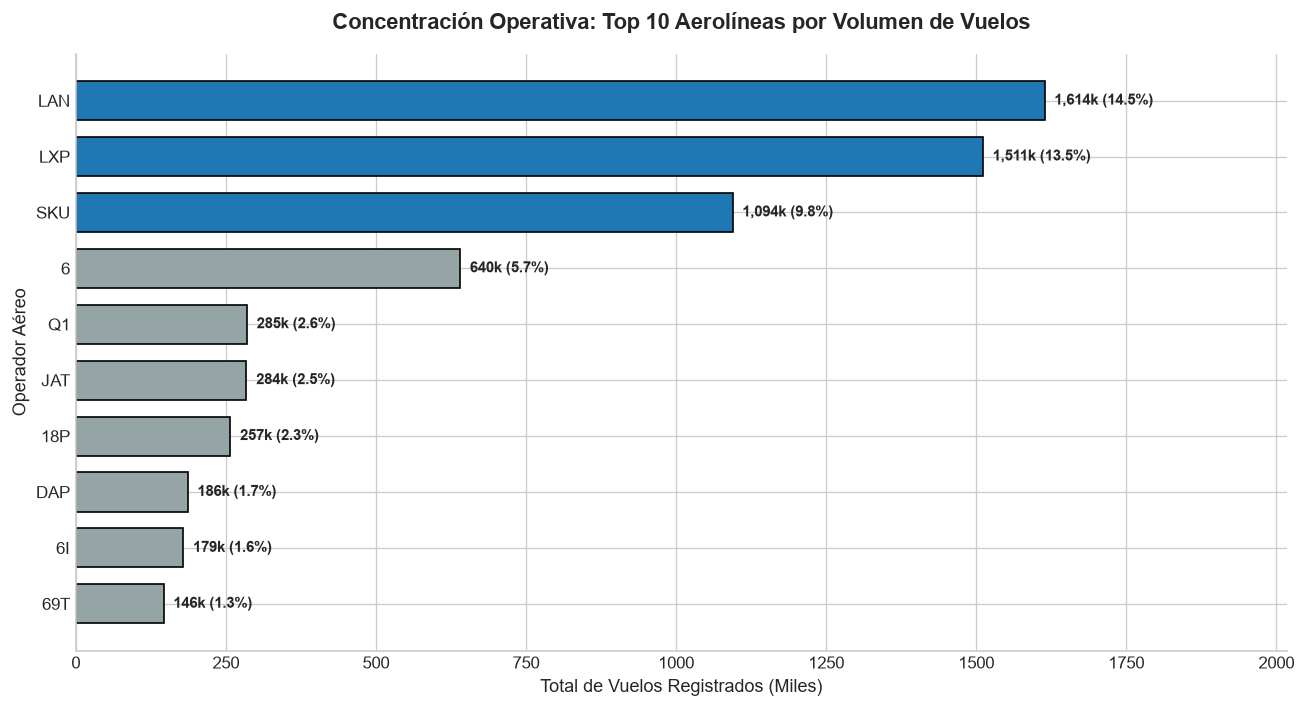

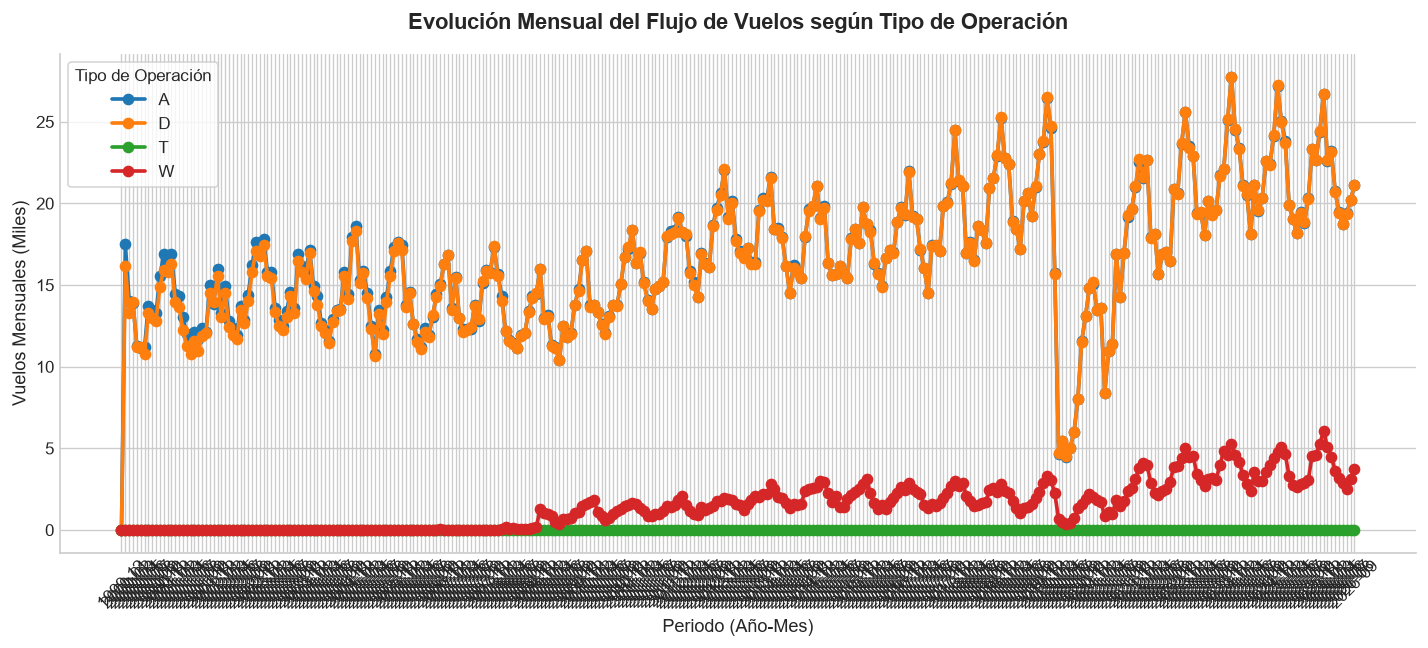

In [8]:
# --- VISUALIZACIÓN 1 (MATPLOTLIB): Comparación Top 10 Aerolíneas ---
# Ordenamos de menor a mayor para que el más grande quede arriba en el gráfico
top10_aero = agg_simple.head(10).sort_values(by='total_vuelos', ascending=True)

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)

# Destacamos las 3 aerolíneas principales con color azul, y el resto en gris
colores = ['#95a5a6' if i < len(top10_aero)-3 else '#1f77b4' for i in range(len(top10_aero))]

barras = ax.barh(
    top10_aero['aerolinea_dgac'],
    top10_aero['total_vuelos'] / 1000, # Dividimos por 1000 para que el eje diga "Miles de vuelos"
    color=colores,
    edgecolor='black',
    height=0.7
)

# Etiquetas de datos en cada barra
for barra, pct in zip(barras, top10_aero['participacion_pct']):
    ancho = barra.get_width()
    ax.text(
        ancho + (top10_aero['total_vuelos'].max() / 1000) * 0.01,
        barra.get_y() + barra.get_height()/2,
        f"{ancho:,.0f}k ({pct:.1f}%)",
        va='center', ha='left', fontsize=9, fontweight='bold'
    )

ax.set_title("Concentración Operativa: Top 10 Aerolíneas por Volumen de Vuelos", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Total de Vuelos Registrados (Miles)", fontsize=11)
ax.set_ylabel("Operador Aéreo", fontsize=11)
ax.set_xlim(0, (top10_aero['total_vuelos'].max() / 1000) * 1.25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()
fig.savefig(f"{FIGURES_DIR}01_matplotlib_comparacion_operadores.png", dpi=300)
plt.show()


# --- VISUALIZACIÓN 2 (MATPLOTLIB): Evolución Mensual ---
fig, ax = plt.subplots(figsize=(12, 5.5), dpi=120)

# Dibujamos una línea por cada tipo de operación (columna de nuestra tabla pivote)
for idx, col in enumerate(tabla_pivote.columns):
    ax.plot(
        tabla_pivote.index,
        tabla_pivote[col] / 1000, 
        marker='o',
        linewidth=2.2,
        label=str(col)
    )

ax.set_title("Evolución Mensual del Flujo de Vuelos según Tipo de Operación", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Periodo (Año-Mes)", fontsize=11)
ax.set_ylabel("Vuelos Mensuales (Miles)", fontsize=11)
ax.tick_params(axis='x', rotation=45)
ax.legend(title="Tipo de Operación", frameon=True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()
fig.savefig(f"{FIGURES_DIR}02_matplotlib_evolucion_temporal.png", dpi=300)
plt.show()